In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

# ---- given values (assignment) ----
H_DEPTH = 25.0     # water depth h [m]
HS      = 7.0      # significant wave height [m]
G       = 9.81     # gravitational acceleration [m/s2]

# ---- assumptions ----
KA      = 0.25     # wave steepness ka [-] (step 1)
GAMMA   = 3.3      # JONSWAP peak enhancement factor [-]
SIGMA_A, SIGMA_B = 0.07, 0.09   # JONSWAP peak width for f <= fp and f > fp

# ---- plot style (same as the flow notebooks) ----
BLUE, ORANGE = "#2a78d6", "#eb6834"
def style(ax, title):
    ax.set_title(title)
    ax.grid(True, color="0.88", lw=0.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

# ---- small helper functions ----
def omega_full(k, h=H_DEPTH):
    # full dispersion relation, valid for all depths: w^2 = g k tanh(kh)
    return np.sqrt(G * k * np.tanh(k * h))

def omega_deep(k):
    # deep-water approximation: w^2 = g k
    return np.sqrt(G * k)

def regime(kh):
    if kh > np.pi:
        return "deep water"
    if kh < np.pi / 10:
        return "shallow water"
    return "intermediate depth"

def E_pm(f, hs, fp):
    # Pierson-Moskowitz spectrum written in Hs and fp [m2/Hz]
    return 5 / 16 * hs**2 * fp**4 * f**-5 * np.exp(-5 / 4 * (fp / f)**4)

def E_jonswap(f, hs, fp, gamma=GAMMA, sa=SIGMA_A, sb=SIGMA_B):
    # JONSWAP spectrum: PM shape x peak enhancement, normalised with A_gamma [m2/Hz]
    a_gamma = 1 - 0.287 * np.log(gamma)
    sigma = np.where(f <= fp, sa, sb)
    peak = gamma ** np.exp(-(f - fp)**2 / (2 * sigma**2 * fp**2))
    return a_gamma * E_pm(f, hs, fp) * peak

Target Hs:     7.000 m
Simulated Hs:  7.076 m
Mean eta:      -0.0003 m (expected ~0)
Skewness eta:  0.0478 (expected ~0 for linear Gaussian waves)
Kurtosis eta:  3.2842 (expected ~3)
Max |u(0,t)|:  5.440 m/s


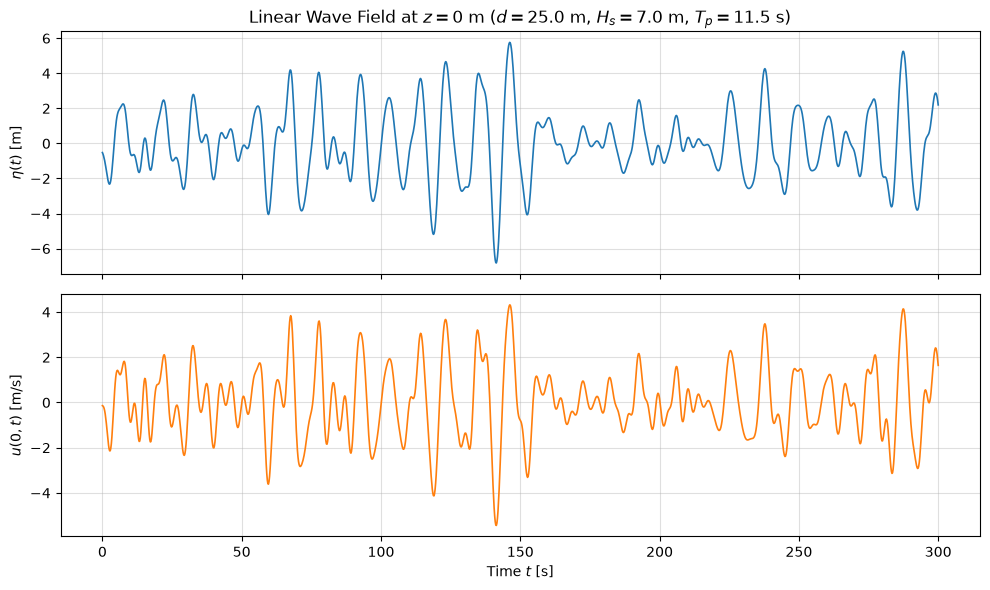

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from scipy.stats import skew, kurtosis

# ==========================================
# 1. Input Parameters (Student Number = 6)
# ==========================================
g = 9.81          # Gravitational acceleration [m/s^2]
d = 25.0          # Water depth [m]
Hs = 7.0          # Significant wave height [m]
Tp = 11.5         # Peak wave period [s] (replace if specified earlier in assignment)
gamma = 3.3       # JONSWAP peak enhancement factor
z = 0.0           # Vertical coordinate [m] (z = 0 at Mean Water Level)

# ==========================================
# 2. Time and Frequency Discretization
# ==========================================
T_dur = 1800.0    # Simulation duration [s] (30 minutes)
dt = 0.2          # Time step [s]
t = np.arange(0, T_dur, dt)

fp = 1.0 / Tp
f_min = 0.4 * fp
f_max = 3.5 * fp
N = 500           # Number of frequency components

f = np.linspace(f_min, f_max, N)
df = f[1] - f[0]
omega = 2.0 * np.pi * f

# ==========================================
# 3. JONSWAP Wave Spectrum E(f)
# ==========================================
sigma = np.where(f <= fp, 0.07, 0.09)
E_raw = (f**-5) * np.exp(-1.25 * (fp / f)**4) * (gamma ** np.exp(-0.5 * ((f - fp) / (sigma * fp))**2))

# Scale spectrum so that Hs = 4 * sqrt(m0) exactly
m0_target = (Hs / 4.0)**2
m0_raw = np.trapezoid(E_raw, f)  # Use np.trapz if on NumPy < 2.0
E = E_raw * (m0_target / m0_raw)

# Component amplitudes and uniform random phases
rng = np.random.default_rng(seed=42)
a = np.sqrt(2.0 * E * df)
phi = rng.uniform(0.0, 2.0 * np.pi, size=N)

# ==========================================
# 4. Solve Linear Dispersion Relation
#    omega^2 = g * k * tanh(k * d)
# ==========================================
k = np.zeros(N)
for i, w in enumerate(omega):
    k_guess = w**2 / g  # Deep-water initial guess
    k[i] = fsolve(lambda kn: w**2 - g * kn * np.tanh(kn * d), k_guess)[0]

# ==========================================
# 5. Linear Time Series at (x, y) = (0, 0)
# ==========================================
# Phase matrix of shape (len(t), N)
theta = np.outer(t, omega) + phi

# Surface elevation: eta(t) = sum[ a_n * cos(omega_n * t + phi_n) ]
eta = np.cos(theta) @ a

# Horizontal orbital velocity: u(z, t) = sum[ a_n * omega_n * cosh(k_n*(z+d))/sinh(k_n*d) * cos(...) ]
u_transfer = omega * np.cosh(k * (z + d)) / np.sinh(k * d)
u = np.cos(theta) @ (a * u_transfer)

# ==========================================
# 6. Basic Verification Checks
# ==========================================
Hs_sim = 4.0 * np.std(eta)
print(f"Target Hs:     {Hs:.3f} m")
print(f"Simulated Hs:  {Hs_sim:.3f} m")
print(f"Mean eta:      {np.mean(eta):.4f} m (expected ~0)")
print(f"Skewness eta:  {skew(eta):.4f} (expected ~0 for linear Gaussian waves)")
print(f"Kurtosis eta:  {kurtosis(eta, fisher=False):.4f} (expected ~3)")
print(f"Max |u(0,t)|:  {np.max(np.abs(u)):.3f} m/s")

# ==========================================
# 7. Plot First 300 Seconds
# ==========================================
mask = t <= 300.0
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(t[mask], eta[mask], color='tab:blue', linewidth=1.2)
ax1.set_ylabel(r'$\eta(t)$ [m]')
ax1.set_title(f'Linear Wave Field at $z = 0$ m ($d = {d}$ m, $H_s = {Hs}$ m, $T_p = {Tp}$ s)')
ax1.grid(True, alpha=0.4)

ax2.plot(t[mask], u[mask], color='tab:orange', linewidth=1.2)
ax2.set_xlabel('Time $t$ [s]')
ax2.set_ylabel(r'$u(0, t)$ [m/s]')
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

<>:79: SyntaxWarning: invalid escape sequence '\e'
<>:80: SyntaxWarning: invalid escape sequence '\e'
<>:79: SyntaxWarning: invalid escape sequence '\e'
<>:80: SyntaxWarning: invalid escape sequence '\e'
C:\Users\jacob\AppData\Local\Temp\ipykernel_33560\617878407.py:79: SyntaxWarning: invalid escape sequence '\e'
  ax1.plot(t, eta_1, '--', label='Linear $\eta^{(1)}(t)$', alpha=0.8)
C:\Users\jacob\AppData\Local\Temp\ipykernel_33560\617878407.py:80: SyntaxWarning: invalid escape sequence '\e'
  ax1.plot(t, eta_tot, label='Total wave field(with 2nd-order) $\eta(t)$')


Characteristic wavenumber kp: 0.0714 rad/m (kp*h = 1.79)
Linear skewness: 0.036 | 2nd-order skewness: 0.551
Max crest (linear): 6.88 m | Max crest (2nd-order): 8.98 m
Min trough (linear): -6.80 m | Min trough (2nd-order): -4.92 m


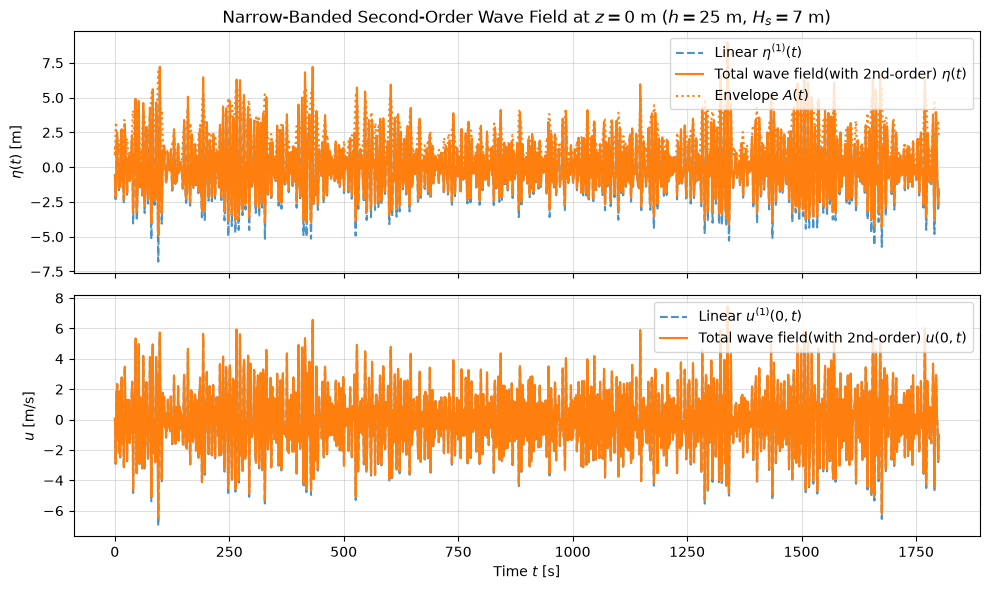

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from scipy.signal import hilbert
from scipy.stats import skew


#Parameters according to Student Number
g = 9.81          # Gravity [m/s^2]
h = 25.0          # Water depth d [m]
Hs = 7.0          # Significant wave height [m]

#Other given or known parameters
Tp = 7.72         # Peak period [s] (taken from question 3)
gamma = 3.3       # JONSWAP peak enhancement factor
sigma_a, sigma_b = 0.07, 0.09   # JONSWAP peak width for f <= fp and f > fp
z = 0.0           #Elevation [m] (Taken as z=0)

#Part a: Applying Linear wave theory to model the time series
#Time discretization
T_dur = 1800.0      #Duration [s] (30 minutes)
dt = 0.2            #Time step [s]
t = np.arange(0, T_dur, dt)

#Frequency discretization and peak values
fp = 1.0 / Tp           #Peak frequency [Hz]
wp = 2.0 * np.pi * fp   #Peak omega [Hz]

f = np.linspace(0.4*fp, 3.5*fp, 500)
df = f[1] - f[0]        #Frequency stepsize [Hz]
omega = 2.0 * np.pi * f

#Jonswap wave spectrum used from question 3
E = E_jonswap(f, Hs, fp, gamma=gamma, sa=sigma_a, sb=sigma_b)

#Taking amplitudes and random phases for every frequency component
rng = np.random.default_rng(seed=42)
a = np.sqrt(2.0 * E * df)
phi = rng.uniform(0.0, 2.0 * np.pi, size=len(f))

#Solving the dispersion relation for all of the frequency components and for 
#the peak frequency wp(fp)
k = np.array([fsolve(lambda kn: w**2 - g * kn * np.tanh(kn * h), w**2 / g)[0] for w in omega])
kp = fsolve(lambda kn: wp**2 - g * kn * np.tanh(kn * h), wp**2 / g)[0]

#Implementing the linear wave theory and use the formulas to model the time series
theta_mat = np.outer(t, omega) + phi
eta_1 = np.cos(theta_mat) @ a
u_1 = np.cos(theta_mat) @ (a * omega * np.cosh(k * (z + h)) / np.sinh(k * h))


#Part b: Narrow-Banded 2nd-Order Super-Harmonics
#Taking the hilbert transform of the linear model and compute the A_inst and theta_inst
analytic_signal = hilbert(eta_1)
A_inst = np.abs(analytic_signal)
H_inst = 2.0 * A_inst
theta_inst = np.angle(analytic_signal)

#Using the second order formulas for eta and u
eta_2_amp = (H_inst**2 * kp / 16.0) * (np.cosh(kp * h) / np.sinh(kp * h)**3) * (2.0 + np.cosh(2.0 * kp * h))
eta_2 = eta_2_amp * np.cos(2.0 * theta_inst)

u_2_amp = (3.0 / 16.0) * (H_inst**2 * wp * kp) * (np.cosh(2.0 * kp * (z + h)) / np.sinh(kp * h)**4)
u_2 = u_2_amp * np.cos(2.0 * theta_inst)

#Total second-order signals
eta_tot = eta_1 + eta_2
u_tot = u_1 + u_2

#Verification Prints & Plots

print(f"Characteristic wavenumber kp: {kp:.4f} rad/m (kp*h = {kp*h:.2f})")
print(f"Linear skewness: {skew(eta_1):.3f} | 2nd-order skewness: {skew(eta_tot):.3f}")
print(f"Max crest (linear): {np.max(eta_1):.2f} m | Max crest (2nd-order): {np.max(eta_tot):.2f} m")
print(f"Min trough (linear): {np.min(eta_1):.2f} m | Min trough (2nd-order): {np.min(eta_tot):.2f} m")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(t, eta_1, '--', label='Linear $\eta^{(1)}(t)$', alpha=0.8)
ax1.plot(t, eta_tot, label='Total wave field(with 2nd-order) $\eta(t)$')
ax1.plot(t, A_inst, ':', color='tab:orange', label='Envelope $A(t)$')
ax1.set_ylabel(r'$\eta(t)$ [m]')
ax1.set_title('Narrow-Banded Second-Order Wave Field at $z = 0$ m ($h = 25$ m, $H_s = 7$ m)')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.4)

ax2.plot(t, u_1, '--', label='Linear $u^{(1)}(0,t)$', alpha=0.8)
ax2.plot(t, u_tot, label='Total wave field(with 2nd-order) $u(0,t)$')
ax2.set_xlabel('Time $t$ [s]')
ax2.set_ylabel(r'$u$ [m/s]')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()